# Review Prediction EDA

This notebook explores the factors influencing `review_score` to inform our new problem statement: predicting satisfaction and isolating seller-specific impact.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Load the dataset
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (94480, 33)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,seller_id,...,seller_city,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actual_delivery_days,estimated_delivery_days,delivery_delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0,3504c0cb71d7fa48d967e0e4c94d59d9,...,maua,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,8.0,15,-7.0,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0,289cdb325fb7e7f891c38608bf9e0962,...,belo horizonte,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,13.0,19,-6.0,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0,4869f7a5dfa277a7dca6462dcf3b52b2,...,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,9.0,26,-17.0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,5.0,66922902710d126a0e7d26b0e3805106,...,belo horizonte,MG,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,13.0,26,-13.0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,5.0,2c9e548be18521d1c43cde1c582c6de8,...,mogi das cruzes,SP,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,2.0,12,-10.0,0


## 1. Distribution of Review Scores

C:\Users\Devyansh\AppData\Local\Temp\ipykernel_23400\398621496.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='review_score', data=df, palette='viridis')


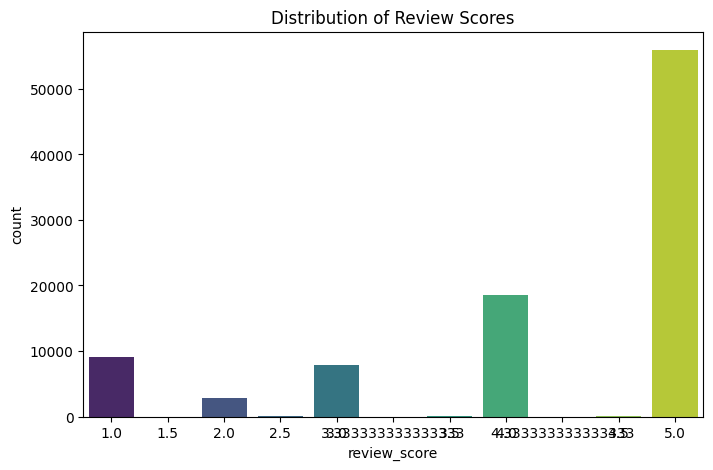

In [2]:
plt.figure(figsize=(8, 5))
sns.countplot(x='review_score', data=df, palette='viridis')
plt.title('Distribution of Review Scores')
plt.show()

## 2. Correlation with Review Score

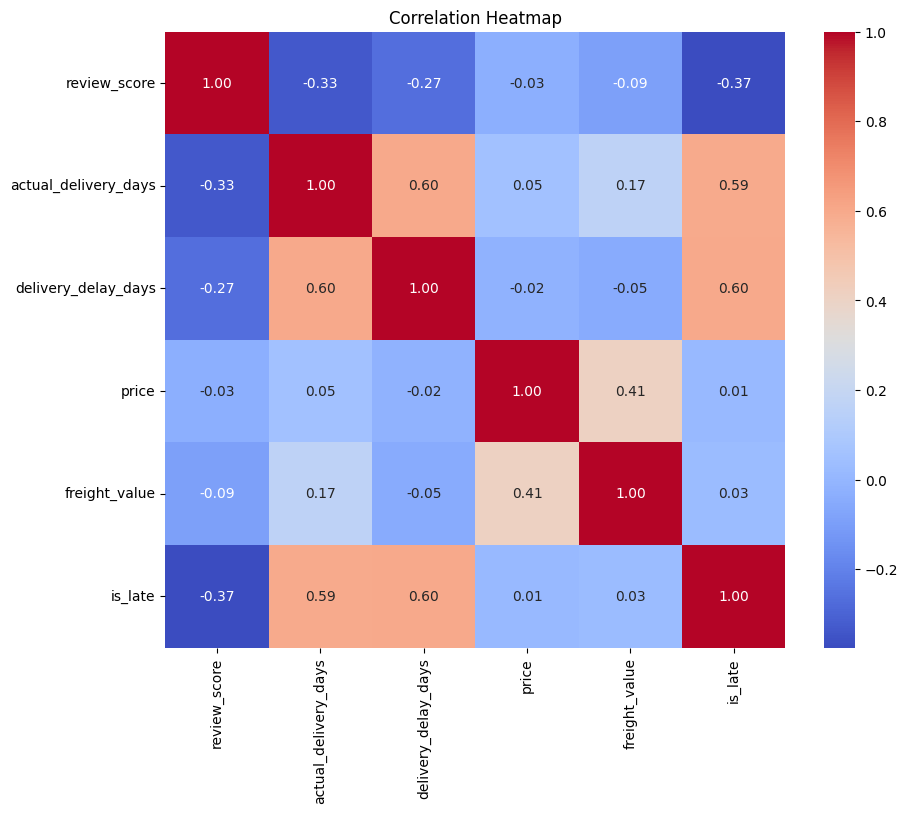

In [3]:
numerical_cols = ['review_score', 'actual_delivery_days', 'delivery_delay_days', 'price', 'freight_value', 'is_late']
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 3. Impact of Lateness on Satisfaction

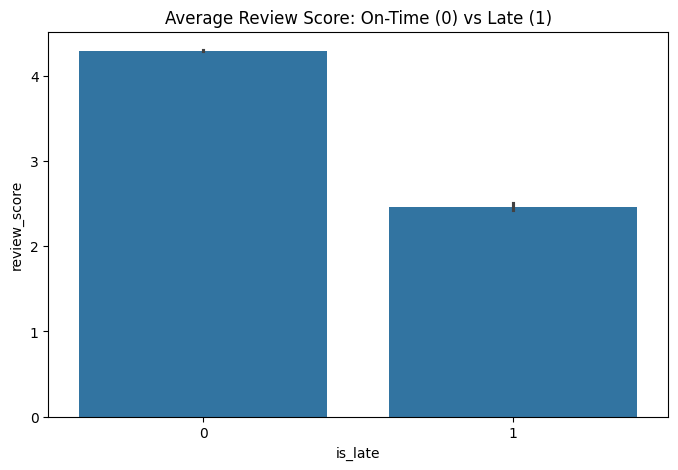

In [4]:
plt.figure(figsize=(8, 5))
sns.barplot(x='is_late', y='review_score', data=df)
plt.title('Average Review Score: On-Time (0) vs Late (1)')
plt.show()